In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

data_dir = "/content/drive/Shareddrives/PRJ303_Dataset/dataset"

print(os.listdir(data_dir))

['erase', 'screenshot', 'clear', 'draw', 'color', 'scroll', 'cursor']


In [ ]:
for label in os.listdir(data_dir):
    path = os.path.join(data_dir, label)
    print(label, ":", len(os.listdir(path)))

erase : 100
screenshot : 100
clear : 100
draw : 100
color : 100
scroll : 100
cursor : 100


In [ ]:
import numpy as np

sample_path = os.path.join(data_dir, os.listdir(data_dir)[0])
sample_file = os.listdir(sample_path)[0]

data = np.load(os.path.join(sample_path, sample_file))

print("Shape:", data.shape)

Shape: (50, 126)


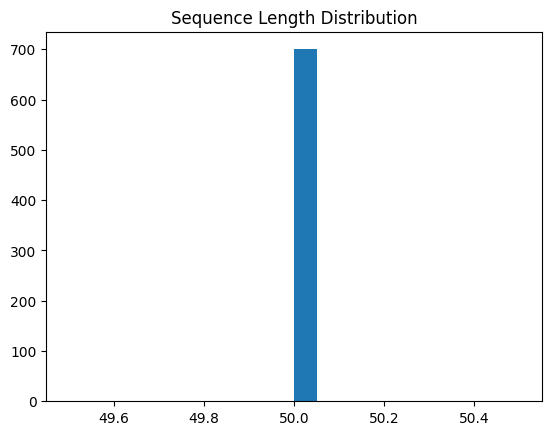

In [ ]:
import matplotlib.pyplot as plt
lengths = []

for label in os.listdir(data_dir):
    path = os.path.join(data_dir, label)
    for file in os.listdir(path):
        data = np.load(os.path.join(path, file))
        lengths.append(len(data))

plt.hist(lengths, bins=20)
plt.title("Sequence Length Distribution")
plt.show()

In [ ]:
class GestureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def load_data(data_dir, seq_len=50):
    X, y = [], []
    label_map = {}

    for i, label in enumerate(sorted(os.listdir(data_dir))):
        label_map[label] = i
        label_path = os.path.join(data_dir, label)

        for file in os.listdir(label_path):
            path = os.path.join(label_path, file)
            data = np.load(path)

            # FIX SEQUENCE LENGTH
            if len(data) > seq_len:
                data = data[:seq_len]
            elif len(data) < seq_len:
                pad = np.zeros((seq_len - len(data), data.shape[1]))
                data = np.vstack((data, pad))

            X.append(data)
            y.append(i)

    return np.array(X), np.array(y), label_map

In [ ]:
X, y, label_map = load_data(data_dir, seq_len=50)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp)

In [ ]:
train_dataset = GestureDataset(X_train, y_train)
val_dataset = GestureDataset(X_val, y_val)
test_dataset = GestureDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
class GestureTransformer(nn.Module):
    def __init__(self, input_dim=126, d_model=128, nhead=8, num_layers=3, num_classes=5):
        super().__init__()
        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_embedding = nn.Parameter(torch.randn(1, 50, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        x = x + self.pos_embedding[:, :x.size(1), :]
        x = self.transformer(x)
        x = x.mean(dim=1)
        return self.fc(x)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
model = GestureTransformer(num_classes=len(label_map)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

In [ ]:
def train(model, loader):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

In [ ]:
epochs = 30
patience = 5
best_val_acc = 0.0
epochs_no_improve = 0

In [ ]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

In [ ]:
for epoch in range(epochs):
    train_loss,train_acc = train(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    scheduler.step()

    print(f"Epoch {epoch+1} | Loss: {train_loss:.4f} | Val Acc: {val_acc:.4f}")

    # Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_no_improve = 0
        # Save best model
        torch.save(model.state_dict(), "best_gesture_transformer.pth")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping triggered after epoch {epoch+1}")
            break

# Load best model for testing
model.load_state_dict(torch.load("best_gesture_transformer.pth"))

Epoch 1 | Loss: 1.8469 | Val Acc: 0.2857
Epoch 2 | Loss: 1.5786 | Val Acc: 0.4286
Epoch 3 | Loss: 1.4552 | Val Acc: 0.4762
Epoch 4 | Loss: 1.3286 | Val Acc: 0.4000
Epoch 5 | Loss: 1.3921 | Val Acc: 0.5333
Epoch 6 | Loss: 1.2846 | Val Acc: 0.5429
Epoch 7 | Loss: 1.0868 | Val Acc: 0.6190
Epoch 8 | Loss: 1.0177 | Val Acc: 0.6190
Epoch 9 | Loss: 0.9291 | Val Acc: 0.6190
Epoch 10 | Loss: 0.8334 | Val Acc: 0.7238
Epoch 11 | Loss: 0.7170 | Val Acc: 0.8571
Epoch 12 | Loss: 0.6035 | Val Acc: 0.8286
Epoch 13 | Loss: 0.5437 | Val Acc: 0.8667
Epoch 14 | Loss: 0.4399 | Val Acc: 0.9143
Epoch 15 | Loss: 0.4014 | Val Acc: 0.8952
Epoch 16 | Loss: 0.3701 | Val Acc: 0.8286
Epoch 17 | Loss: 0.3995 | Val Acc: 0.9048
Epoch 18 | Loss: 0.3368 | Val Acc: 0.9048
Epoch 19 | Loss: 0.3226 | Val Acc: 0.8571
Early stopping triggered after epoch 19


<All keys matched successfully>

In [ ]:
test_acc = evaluate(model, test_loader)
print("Test Accuracy:", test_acc)

Test Accuracy: (0.4703894704580307, 0.8666666666666667)


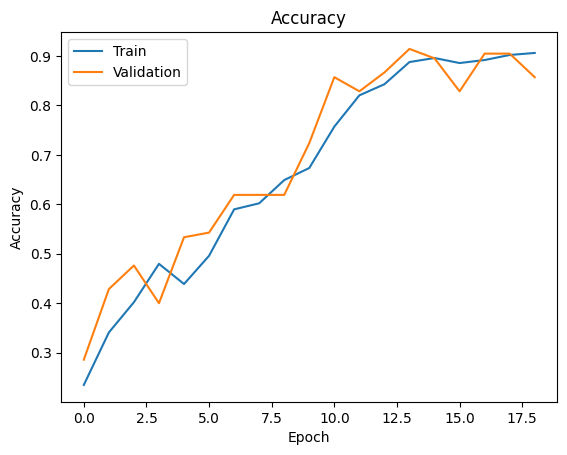

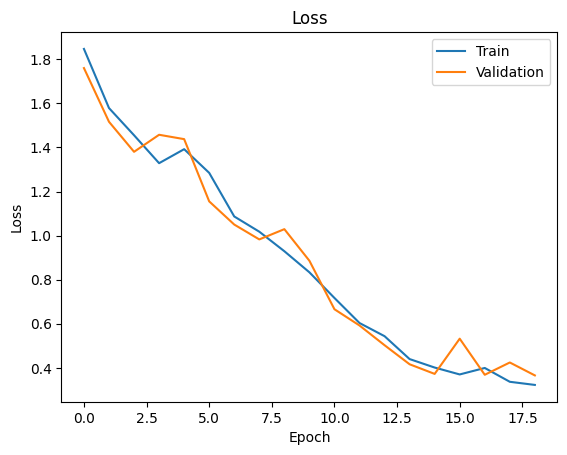

In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure()
plt.plot(train_accuracies)
plt.plot(val_accuracies)
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

# Loss
plt.figure()
plt.plot(train_losses)
plt.plot(val_losses)
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

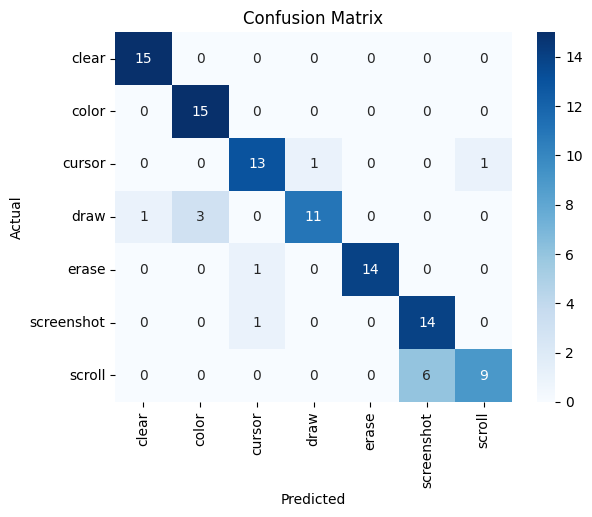

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_map.keys(),
            yticklabels=label_map.keys())
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(all_labels, all_preds, target_names=label_map.keys()))

              precision    recall  f1-score   support

       clear       0.94      1.00      0.97        15
       color       0.83      1.00      0.91        15
      cursor       0.87      0.87      0.87        15
        draw       0.92      0.73      0.81        15
       erase       1.00      0.93      0.97        15
  screenshot       0.70      0.93      0.80        15
      scroll       0.90      0.60      0.72        15

    accuracy                           0.87       105
   macro avg       0.88      0.87      0.86       105
weighted avg       0.88      0.87      0.86       105



In [ ]:
pip uninstall mediapipe -y

Found existing installation: mediapipe 0.10.33
Uninstalling mediapipe-0.10.33:
  Successfully uninstalled mediapipe-0.10.33


In [ ]:
pip install mediapipe==0.10.13

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.6/35.6 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 10.2 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.38.0 requires protobuf<7.0,>=5.0, but you have protobuf 4.25.9 which is incompatible.
grain 0.2.16 requires protobuf>=5.28.3, but you have protobuf 4.25.9 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 4.25.9 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.


Click 'Capture' in the camera window that appears.


<IPython.core.display.Javascript object>

Photo saved as photo.jpg


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


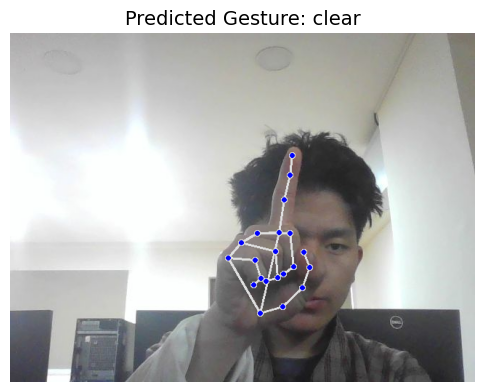

Predicted gesture: clear


In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from google.colab import files

# Initialize MediaPipe Hands
mp_hands = mp.solutions.hands
hands = mp_hands.Hands(static_image_mode=True, max_num_hands=2, min_detection_confidence=0.5)
mp_drawing = mp.solutions.drawing_utils

def extract_landmarks_126(image_path):
    """
    Extract hand landmarks and return a 126-dim vector per frame.
    Strategy: if 2 hands detected, use both (21*3*2 = 126).
    If 1 hand detected, duplicate its landmarks to simulate 2 hands.
    If no hand, return zeros.
    """
    img = cv2.imread(image_path)
    if img is None:
        return None, None
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    results = hands.process(rgb)

    annotated = rgb.copy()
    landmarks_126 = np.zeros(126, dtype=np.float32)

    if results.multi_hand_landmarks:
        # If we have 2 hands, use both
        if len(results.multi_hand_landmarks) == 2:
            all_lms = []
            for hand_idx, hand_landmarks in enumerate(results.multi_hand_landmarks):
                mp_drawing.draw_landmarks(annotated, hand_landmarks, mp_hands.HAND_CONNECTIONS)
                for lm in hand_landmarks.landmark:
                    all_lms.extend([lm.x, lm.y, lm.z])
            if len(all_lms) == 126:  # 2 hands * 21 * 3
                landmarks_126 = np.array(all_lms, dtype=np.float32)
        else:
            # Only one hand detected – duplicate it to make 126 features
            hand = results.multi_hand_landmarks[0]
            mp_drawing.draw_landmarks(annotated, hand, mp_hands.HAND_CONNECTIONS)
            single = []
            for lm in hand.landmark:
                single.extend([lm.x, lm.y, lm.z])
            # Duplicate to simulate second hand
            landmarks_126 = np.array(single + single, dtype=np.float32)
    else:
        return None, annotated  # No hand at all

    return landmarks_126, annotated

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = 'Capture';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

            await new Promise((resolve) => capture.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

try:
    print("Click 'Capture' in the camera window that appears.")
    photo_path = take_photo()
    print(f"Photo saved as {photo_path}")

    landmarks_126, annotated = extract_landmarks_126(photo_path)

    if landmarks_126 is not None:
        # Repeat the same frame 50 times to match training sequence length
        seq_len = 50
        sequence = [landmarks_126] * seq_len
        input_tensor = torch.tensor(np.array(sequence), dtype=torch.float32).unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            output = model(input_tensor)
            pred_idx = torch.argmax(output, dim=1).item()
            pred_label = list(label_map.keys())[pred_idx]

        # Display result
        plt.figure(figsize=(6,6))
        plt.imshow(annotated)
        plt.title(f"Predicted Gesture: {pred_label}", fontsize=14)
        plt.axis('off')
        plt.show()

        print(f"Predicted gesture: {pred_label}")
    else:
        print("No hand detected in the captured image. Please ensure your hand is clearly visible and try again.")

except Exception as e:
    print(f"Error: {e}")
    print("Camera access may not be supported. Try the image upload method below.")

In [ ]:
train_flat = X_train.reshape(-1, X_train.shape[-1])  # (n_samples * seq_len, 126)
# Remove rows that are all zeros (padded frames)
mask = ~np.all(train_flat == 0, axis=1)
train_flat_filtered = train_flat[mask]
mean = train_flat_filtered.mean(axis=0)
std = train_flat_filtered.std(axis=0)
std[std == 0] = 1  # avoid division by zero

In [ ]:
# Normalization function
def normalize(X, mean, std):
    # X shape: (n_samples, seq_len, 126)
    # Apply per-feature normalization
    return (X - mean) / std

# Apply to all sets
X_train_norm = normalize(X_train, mean, std)
X_val_norm = normalize(X_val, mean, std)
X_test_norm = normalize(X_test, mean, std)

# Now use these normalized arrays in the datasets
train_dataset = GestureDataset(X_train_norm, y_train)
val_dataset = GestureDataset(X_val_norm, y_val)
test_dataset = GestureDataset(X_test_norm, y_test)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
np.save("mean.npy", mean)
np.save("std.npy", std)

In [ ]:
class GestureTransformer(nn.Module):
    def __init__(self, input_dim=126, d_model=128, nhead=8, num_layers=3, num_classes=5):
        super().__init__()
        self.embedding = nn.Linear(input_dim, d_model)
        self.pos_embedding = nn.Parameter(torch.randn(1, 50, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        x = x + self.pos_embedding[:, :x.size(1), :]
        x = self.transformer(x)
        x = x.mean(dim=1)
        return self.fc(x)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
model = GestureTransformer(num_classes=len(label_map)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

In [ ]:
def train(model, loader):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

In [ ]:
epochs = 30
patience = 5
best_val_acc = 0.0
epochs_no_improve = 0

In [ ]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

In [ ]:
for epoch in range(epochs):
    train_loss,train_acc = train(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    scheduler.step()

    print(f"Epoch {epoch+1} | Loss: {train_loss:.4f} | Val Acc: {val_acc:.4f}")

    # Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_no_improve = 0
        # Save best model
        torch.save(model.state_dict(), "best_gesture_transformer.pth")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping triggered after epoch {epoch+1}")
            break

# Load best model for testing
model.load_state_dict(torch.load("best_gesture_transformer.pth"))

Epoch 1 | Loss: 1.1816 | Val Acc: 0.8667
Epoch 2 | Loss: 0.5108 | Val Acc: 0.9619
Epoch 3 | Loss: 0.2242 | Val Acc: 0.9524
Epoch 4 | Loss: 0.1276 | Val Acc: 0.9905
Epoch 5 | Loss: 0.0643 | Val Acc: 0.9810
Epoch 6 | Loss: 0.0642 | Val Acc: 0.9905
Epoch 7 | Loss: 0.0400 | Val Acc: 0.9905
Epoch 8 | Loss: 0.0169 | Val Acc: 0.9905
Epoch 9 | Loss: 0.0137 | Val Acc: 0.9905
Early stopping triggered after epoch 9


<All keys matched successfully>

In [ ]:
test_acc = evaluate(model, test_loader)
print("Test Accuracy:", test_acc)

Test Accuracy: (0.19237269088625908, 0.9428571428571428)


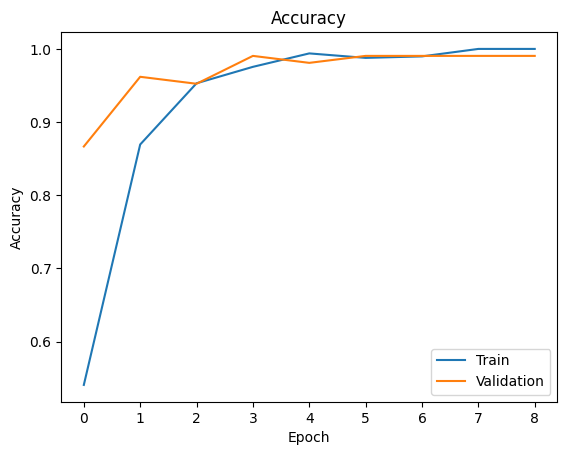

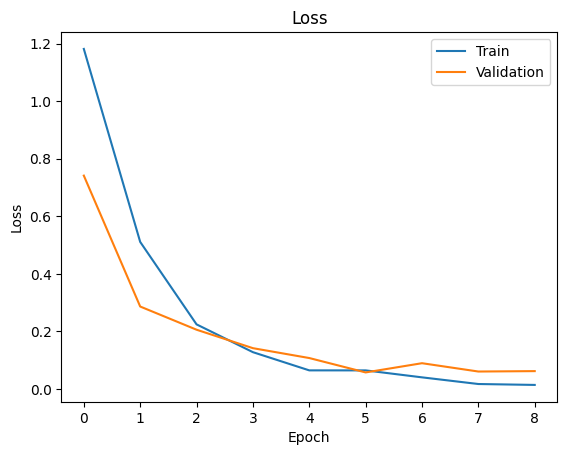

In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure()
plt.plot(train_accuracies)
plt.plot(val_accuracies)
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

# Loss
plt.figure()
plt.plot(train_losses)
plt.plot(val_losses)
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(y_batch.numpy())

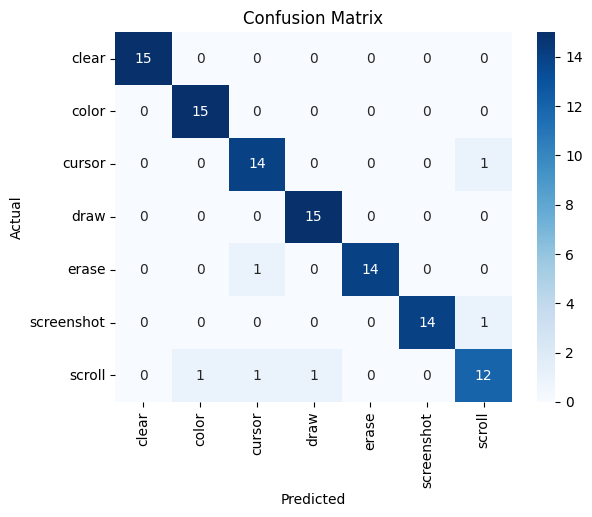

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_map.keys(),
            yticklabels=label_map.keys())
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(all_labels, all_preds, target_names=label_map.keys()))

              precision    recall  f1-score   support

       clear       1.00      1.00      1.00        15
       color       0.94      1.00      0.97        15
      cursor       0.88      0.93      0.90        15
        draw       0.94      1.00      0.97        15
       erase       1.00      0.93      0.97        15
  screenshot       1.00      0.93      0.97        15
      scroll       0.86      0.80      0.83        15

    accuracy                           0.94       105
   macro avg       0.94      0.94      0.94       105
weighted avg       0.94      0.94      0.94       105



Click 'Capture' in the camera window that appears.


<IPython.core.display.Javascript object>

Photo saved as photo.jpg


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


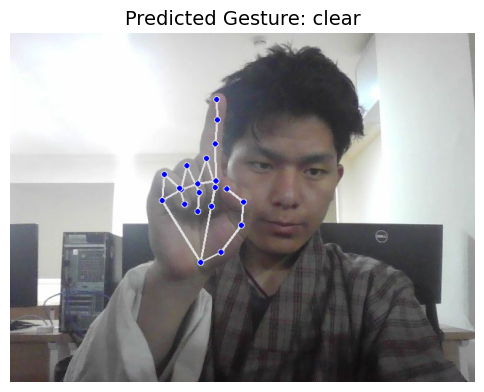

Predicted gesture: clear


In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
model.load_state_dict(torch.load("best_gesture_transformer.pth", map_location=device))
model.eval()

# Load normalization statistics (saved during training)
mean = np.load("mean.npy")
std = np.load("std.npy")
std[std == 0] = 1  # avoid division by zero

mp_hands = mp.solutions.hands
hands = mp_hands.Hands(static_image_mode=True, max_num_hands=2, min_detection_confidence=0.5)
mp_drawing = mp.solutions.drawing_utils

def extract_landmarks_126(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None, None
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    results = hands.process(rgb)
    annotated = rgb.copy()
    landmarks_126 = np.zeros(126, dtype=np.float32)

    if results.multi_hand_landmarks:
        if len(results.multi_hand_landmarks) == 2:
            all_lms = []
            for hand_landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(annotated, hand_landmarks, mp_hands.HAND_CONNECTIONS)
                for lm in hand_landmarks.landmark:
                    all_lms.extend([lm.x, lm.y, lm.z])
            if len(all_lms) == 126:
                landmarks_126 = np.array(all_lms, dtype=np.float32)
        else:
            hand = results.multi_hand_landmarks[0]
            mp_drawing.draw_landmarks(annotated, hand, mp_hands.HAND_CONNECTIONS)
            single = []
            for lm in hand.landmark:
                single.extend([lm.x, lm.y, lm.z])
            landmarks_126 = np.array(single + single, dtype=np.float32)
    else:
        return None, annotated

    return landmarks_126, annotated

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = 'Capture';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

            await new Promise((resolve) => capture.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

try:
    print("Click 'Capture' in the camera window that appears.")
    photo_path = take_photo()
    print(f"Photo saved as {photo_path}")

    landmarks_126, annotated = extract_landmarks_126(photo_path)

    if landmarks_126 is not None:
        # Normalize using training statistics
        landmarks_norm = (landmarks_126 - mean) / std

        # Create sequence of 50 identical normalized frames
        seq_len = 50
        sequence = [landmarks_norm] * seq_len
        input_tensor = torch.tensor(np.array(sequence), dtype=torch.float32).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            pred_idx = torch.argmax(output, dim=1).item()
            pred_label = list(label_map.keys())[pred_idx]

        # Display result
        plt.figure(figsize=(6,6))
        plt.imshow(annotated)
        plt.title(f"Predicted Gesture: {pred_label}", fontsize=14)
        plt.axis('off')
        plt.show()

        print(f"Predicted gesture: {pred_label}")
    else:
        print("No hand detected in the captured image. Please ensure your hand is clearly visible and try again.")

except Exception as e:
    print(f"Error: {e}")
    print("Camera access may not be supported. Try the image upload method below.")